# 04 — Fees (RQ4) and energy per signature (RQ5)

**Fees:** per signature limit, every shortlisted point against the `hw_wallet_safe` point as baseline:
Δbytes → ΔWU → ΔvB → Δsats per input at 2 / 10 / 50 sat/vB (`kb/fees.py`, BIP-360 P2MR script-path spend,
depth 1, 32-byte PQ pubkey). Signature bytes use R = 16 B.

**Energy:** GPU joules per attempt measured by integrating the 10 Hz board-power log over each config's kernel
window (includes launch gaps, so it is the real cost of a batch). Other classes: rate × typical power from
`kb/hardware.yaml` (estimates, labelled).

In [1]:
import sys; sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import common as C
from common import fees
from runner.configs import COMPRESSIONS
OUT = C.out_dir('04_fees_energy')
sl = C.shortlist()
e4 = pd.read_csv(C.OUT / '03_pareto' / 'e4_sign_cost.csv').set_index(['param_id', 'layout'])

## Fee deltas vs. the hardware-wallet-safe point

In [2]:
rows = []
for L, g in sl.groupby('sig_limit_log2'):
    base_pid = g.index[g.profile == 'hw_wallet_safe'][0]
    base = int(g.loc[base_pid, 'sig_bytes'])
    for pid, pt in g.sort_values('sig_bytes').iterrows():
        r = fees.delta_table([int(pt.sig_bytes)], base)[0]
        rows.append({'sig_limit': f'2^{L}', 'param_id': pid, 'profile': pt.profile, 'sig_bytes': int(pt.sig_bytes),
                     'vs_hw_wallet_safe_B': base, 'd_bytes': r['d_bytes'], 'd_vB': r['d_vb'],
                     'd_sats@2': r['d_sats@2'], 'd_sats@10': r['d_sats@10'], 'd_sats@50': r['d_sats@50'],
                     'tx_vB_1in2out': r['tx_vsize_1in2out'], 'pct_of_tx': -r['d_vb'] / fees.tx_vbytes(1, 2, base) * 100})
fz = pd.DataFrame(rows)
C.to_markdown(fz, OUT / 'fee_deltas.md'); fz.to_csv(OUT / 'fee_deltas.csv', index=False)
key = fz[fz.profile.isin(['hw_wallet_safe', 'gpu_signer_moderate', 'gpu_signer_max'])]
key[['sig_limit', 'profile', 'sig_bytes', 'd_bytes', 'd_vB', 'd_sats@10', 'tx_vB_1in2out', 'pct_of_tx']]

,sig_limit,profile,sig_bytes,d_bytes,d_vB,d_sats@10,tx_vB_1in2out,pct_of_tx
0,2^20,gpu_signer_max,2280,-596,-149.0,-1490.0,726,17.028571
1,2^20,gpu_signer_moderate,2504,-372,-93.0,-930.0,782,10.628571
3,2^20,hw_wallet_safe,2876,0,0.0,0.0,875,-0.000000
10,2^30,gpu_signer_max,2664,-792,-198.0,-1980.0,822,19.411765
12,2^30,gpu_signer_moderate,2908,-548,-137.0,-1370.0,883,13.431373
16,2^30,hw_wallet_safe,3456,0,0.0,0.0,1020,-0.000000
28,2^40,gpu_signer_max,2892,-1052,-263.0,-2630.0,879,23.029772
29,2^40,gpu_signer_moderate,3216,-728,-182.0,-1820.0,960,15.936953
31,2^40,hw_wallet_safe,3944,0,0.0,0.0,1142,-0.000000


Negative Δ = saving per input versus the hardware-wallet-safe set. `pct_of_tx` is the saving as a share of a
1-input / 2-output P2MR spend with the baseline signature. Reference: the Kudinov–Nick 2²⁰ point (3,128 B with
R = 32, 3,112 B here) costs `fees.tx_vbytes(1, 2, 3112)` vB.

1-in/2-out P2MR spend, vB: {2280: 726, 2892: 879, 3112: 934, 3456: 1020, 3944: 1142, 64: 172}


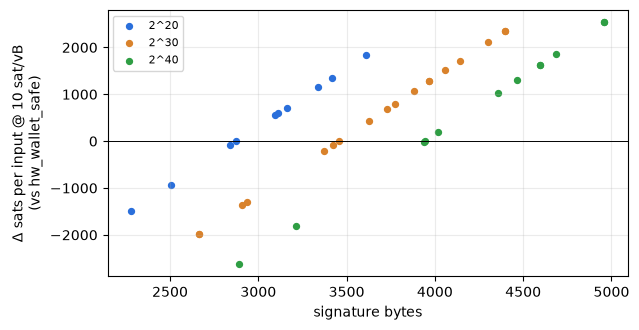

In [3]:
print('1-in/2-out P2MR spend, vB:', {b: fees.tx_vbytes(1, 2, b) for b in (2280, 2892, 3112, 3456, 3944, 64)})
fig, ax = plt.subplots(figsize=(6.5, 3.4))
cols = {'2^20': '#2a6fdb', '2^30': '#d9822b', '2^40': '#2f9e44'}
for L, g in fz.groupby('sig_limit'):
    ax.scatter(g.sig_bytes, g['d_sats@10'], color=cols[L], s=18, label=L)
ax.axhline(0, color='k', lw=0.7); ax.set_xlabel('signature bytes'); ax.set_ylabel('Δ sats per input @ 10 sat/vB\n(vs hw_wallet_safe)')
ax.legend(fontsize=8); ax.grid(alpha=0.25); fig.tight_layout(); fig.savefig(OUT / 'fee_deltas.png', dpi=160)

## GPU energy per attempt, measured

In [4]:
s = C.summary(); pw = C.power()
rows = []
for cid, r in s.iterrows():
    w = C.window(pw, r.start, r.end)
    if len(w) < 20: continue  # < 2 s of telemetry: too short to integrate
    J = C.energy_joules(w)
    tr = r.mean_tries * r.n
    rows.append({'config_id': cid, 'kind': r.kind, 'window_s': (r.end - r.start).total_seconds(), 'joules': J,
                 'mean_W': J / (r.end - r.start).total_seconds(), 'J_per_instance': J / r.n,
                 'nJ_per_attempt': J / tr * 1e9, 'nJ_per_compression': J / (tr * COMPRESSIONS[r.kind]) * 1e9})
cols_en = ['config_id', 'kind', 'window_s', 'joules', 'mean_W', 'J_per_instance', 'nJ_per_attempt', 'nJ_per_compression']
en = pd.DataFrame(rows, columns=cols_en).set_index('config_id')
by = en.groupby('kind')[['nJ_per_attempt', 'nJ_per_compression', 'mean_W']].median()
busy = pw[pw.power_w > 30].power_w.mean()
raw_nJ = busy / C.e0()['median_last_2_3'] * 1e9
print(f"configs with ≥ 2 s telemetry: {len(en)};  raw-SHA energy (busy power / E0 rate): {raw_nJ:.1f} nJ per compression")
C.to_markdown(en.round(3), OUT / 'gpu_energy_configs.md'); C.to_markdown(by.round(3), OUT / 'gpu_energy_by_kind.md')
# layouts without a long enough window (short runs) fall back to the raw-SHA figure x compressions per attempt
nj_attempt = lambda k: by.loc[k, 'nJ_per_attempt'] if k in by.index else raw_nJ * COMPRESSIONS[k]
by

configs with ≥ 2 s telemetry: 32;  raw-SHA energy (busy power / E0 rate): 20.8 nJ per compression


,nJ_per_attempt,nJ_per_compression,mean_W
kind,,,
R,124.488126,20.748021,43.625778
ctr,58.938549,19.646183,41.867754
pors,240.898959,34.414137,44.694955
wots,27.283167,27.283167,44.351924


## Energy per signature, by signer class (mean signing work from notebook 03)

GPU grinding uses the measured nJ/attempt per layout; GPU tree building uses the raw-SHA figure. CPU uses the
45 W PL1 package power over the measured sustained rate (not a power measurement). Other classes from
`kb/hardware.yaml` (typical watts ÷ typical rate).

In [5]:
hw = {c['id']: c for c in C.hardware()['classes']}
lad = C.ladder()
jpc = {}
for cid, r in lad.iterrows():
    if cid == 'class3':
        jpc[cid] = raw_nJ * 1e-9
    elif cid == 'class2':
        jpc[cid] = 45.0 / r.comp_per_s
    else:
        jpc[cid] = hw[cid]['watts']['typical'] / r.comp_per_s
rows = []
for (pid, lay), r in e4.iterrows():
    row = {'param_id': pid, 'layout': lay, 'profile': r.profile, 'sig_bytes': r.sig_bytes}
    for cid, lr in lad.iterrows():
        if cid == 'class3':
            g = r.grind_mean
            # split grind into WOTS+C and FTS parts priced at their measured per-attempt energy
            pt = sl.loc[pid]
            wots_part = pt.d * pt.model_wots_c_per_layer
            fts_part = max(g - wots_part, 0)
            J = r.base_comp * jpc[cid] + wots_part * nj_attempt('wots') * 1e-9
            if lay in COMPRESSIONS: J += fts_part / COMPRESSIONS[lay] * nj_attempt(lay) * 1e-9
        else:
            J = r.total_mean * jpc[cid]
        row[lr.label] = J
    rows.append(row)
ej = pd.DataFrame(rows).set_index(['param_id', 'layout'])
ej.to_csv(OUT / 'joules_per_signature.csv')
C.to_markdown(ej.round(4), OUT / 'joules_per_signature.md')
print(pd.Series(jpc, name='J per compression').map(lambda v: f'{v:.3g}'))
ej[ej.profile.isin(['hw_wallet_safe', 'gpu_signer_moderate', 'gpu_signer_max'])].round(3)

class0a    3.75e-06
class0b    1.25e-06
class1b    1.19e-07
class2     1.93e-07
class3     2.08e-08
class4     2.33e-08
Name: J per compression, dtype: str


,,profile,sig_bytes,"HW wallet MCU, software SHA (Cortex-M4)",HW wallet MCU + SHA peripheral,Raspberry Pi 5 (ARMv8 SHA2),"i5-13420H SHA-NI, 12 threads",RTX 4050 Laptop @ 45 W,8x RTX 4090 server
param_id,layout,,,,,,,,
L20-WCPFP-h24d2-k7a18-w256S1912z1-m94,pors,gpu_signer_moderate,2504,156.728,52.243,4.970,8.078,0.933,0.972
L20-WCPFP-h27d3-k10a12-w256S2040z0-m93,pors,hw_wallet_safe,2876,24.175,8.058,0.767,1.246,0.135,0.150
L20-WCPFP-h32d2-k11a10-w256S1912z1-m68,pors,gpu_signer_max,2280,2199.997,733.332,69.766,113.386,13.346,13.643
L30-WCPFP-h32d2-k7a19-w256S1912z1-m96,pors,gpu_signer_max,2664,2247.338,749.113,71.267,115.826,13.632,13.937
L30-WCPFP-h32d4-k9a15-w256S2040z0-m109,pors,hw_wallet_safe,3456,19.172,6.391,0.608,0.988,0.107,0.119
L30-WCPFP-h33d3-k8a16-w256S1912z1-m94,pors,gpu_signer_moderate,2908,114.735,38.245,3.638,5.913,0.707,0.712
L40-WCPFP-h48d3-k9a13-w256S1912z1-m77,pors,gpu_signer_max,2892,3165.876,1055.292,100.395,163.167,18.786,19.633
L40-WCPFP-h48d4-k9a13-w256S1912z1-m82,pors,gpu_signer_moderate,3216,255.297,85.099,8.096,13.158,1.480,1.583
L40-WCPFP-h48d6-k9a13-w256S2440z0-m91,pors,hw_wallet_safe,3944,24.599,8.200,0.780,1.268,0.137,0.153


At these magnitudes energy is not a constraint for any desktop/GPU signer (≲ 20 J for the largest GPU-signer
point, roughly a laptop running for half a second at 45 W). For MCU wallets the cost shows up as time, not as
battery: a few hundred joules at most for the hardware-wallet-safe points.